# Vì sao RA có lợi rõ hơn trên BCI IV-2a?

Notebook này kiểm tra một cơ chế có thể bác bỏ được, không chỉ trực quan hóa t-SNE:

1. RA có giảm **same-class target-to-source shift** trên session tương lai không?
2. Full-covariance RA có tốt hơn scalar/diagonal normalization không?
3. Trên chính BCI 2a, hiệu ứng thay đổi thế nào khi giảm 22 kênh xuống C3/Cz/C4 hoặc giảm 4 lớp xuống left/right?

Nếu hiệu ứng suy giảm chủ yếu khi giảm số kênh, đó là bằng chứng cho giả thuyết RA hữu ích nhờ sửa spatial covariance/mixing giàu chiều của BCI 2a. Dữ liệu dùng fit RA luôn là session sớm; mọi metric chính được tính trên session đánh giá chưa dùng để fit.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == 'analysis':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from analysis.ra_mechanism_core import run_analysis

pd.set_option('display.max_columns', 50)
OUTPUT = ROOT / 'analysis' / 'ra_mechanism_outputs'

/tmp/tcformer-ra-analysis-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Chạy phân tích

Lần đầu sẽ tải dữ liệu MOABB công khai vào `/tmp/tcformer-ra-data` và cache epoch vào `/tmp/tcformer-ra-epochs`. Những lần sau dùng cache.

In [2]:
results, summary, controlled = run_analysis(
    data_root='/tmp/tcformer-ra-data',
    cache_root='/tmp/tcformer-ra-epochs',
    output_dir=OUTPUT,
)

Loading BCI IV-2a, subject 1 ...


Loading BCI IV-2a, subject 2 ...


Loading BCI IV-2a, subject 3 ...


Loading BCI IV-2a, subject 4 ...


Loading BCI IV-2a, subject 5 ...


...

Loading Zhou2016, subject 2 ...


Loading Zhou2016, subject 3 ...


Loading Zhou2016, subject 4 ...


Analysing Zhou-14ch-3class ...


Saved results to /home/aipro/Documents/Test-2/Tcformer/tcformer-test/analysis/ra_mechanism_outputs


## Kết quả chính

`same_class_reduction_full_pct` là phần trăm giảm khoảng cách từ centroid của từng lớp ở target-evaluation đến centroid cùng lớp của các source-training subjects. `quality_change_full_pct` kết hợp class separation và same-class domain shift; càng lớn càng tốt.

In [3]:
columns = [
    'config', 'n_subjects', 'n_channels', 'n_classes',
    'marginal_reduction_full_pct', 'same_class_reduction_full_pct',
    'quality_change_full_pct', 'mdm_accuracy_none', 'mdm_accuracy_full',
    'mdm_gain_full_pp', 'mdm_full_minus_scalar_pp',
    'p_mdm_none_vs_full', 'p_mdm_scalar_vs_full',
    'p_same_class_none_vs_full',
]
display(summary[columns].round(4))

,config,n_subjects,n_channels,n_classes,marginal_reduction_full_pct,same_class_reduction_full_pct,quality_change_full_pct,mdm_accuracy_none,mdm_accuracy_full,mdm_gain_full_pp,mdm_full_minus_scalar_pp,p_mdm_none_vs_full,p_mdm_scalar_vs_full,p_same_class_none_vs_full
0,2a-22ch-4class,9,22,4,23.9791,22.3305,37.2029,0.3032,0.4252,12.1914,4.8225,0.0039,0.3750,0.0742
1,2a-22ch-LR,9,22,2,21.1135,20.2147,38.7639,0.5378,0.6204,8.2562,2.8549,0.0742,0.9102,0.1641
2,2a-3ch-4class,9,3,4,66.6550,60.8032,195.9290,0.2986,0.3931,9.4522,2.3920,0.0078,0.3008,0.0078
3,2a-3ch-LR,9,3,2,64.3036,60.5584,231.2368,0.5440,0.6042,6.0185,2.0833,0.0977,0.7422,0.0078
4,2b-3ch-LR,9,3,2,64.9990,61.6483,149.8643,0.5666,0.5763,0.9673,-1.9196,0.4961,0.0977,0.0195
5,Zhou-14ch-3class,4,14,3,38.2933,36.7459,49.2938,0.6183,0.7067,8.8333,-4.0000,0.2500,0.2500,0.1250


,config_a,config_b,mean_reduction_a_pct,mean_reduction_b_pct,mean_paired_difference_pct,wilcoxon_p,mean_mdm_gain_a_pp,mean_mdm_gain_b_pp,mean_paired_difference_pp,mean_difference_pp,mann_whitney_p
channel_effect_4class,2a-22ch-4class,2a-3ch-4class,20.752569,54.733577,-33.981008,0.007812,NaN,NaN,NaN,NaN,NaN
channel_effect_LR,2a-22ch-LR,2a-3ch-LR,18.920559,56.663261,-37.742703,0.003906,NaN,NaN,NaN,NaN,NaN
class_effect_22ch,2a-22ch-4class,2a-22ch-LR,20.752569,18.920559,1.83201,0.164062,NaN,NaN,NaN,NaN,NaN
class_effect_3ch,2a-3ch-4class,2a-3ch-LR,54.733577,56.663261,-1.929685,1.0,NaN,NaN,NaN,NaN,NaN
mdm_channel_effect_4class,2a-22ch-4class,2a-3ch-4class,NaN,NaN,NaN,0.25,12.191358,9.45216,2.739198,NaN,NaN
mdm_channel_effect_LR,2a-22ch-LR,2a-3ch-LR,NaN,NaN,NaN,0.203125,8.256173,6.018519,2.237654,NaN,NaN
mdm_2a_vs_2b_matched_design,2a-3ch-LR,2b-3ch-LR,NaN,NaN,NaN,NaN,6.018519,0.967262,NaN,5.051257,0.386508


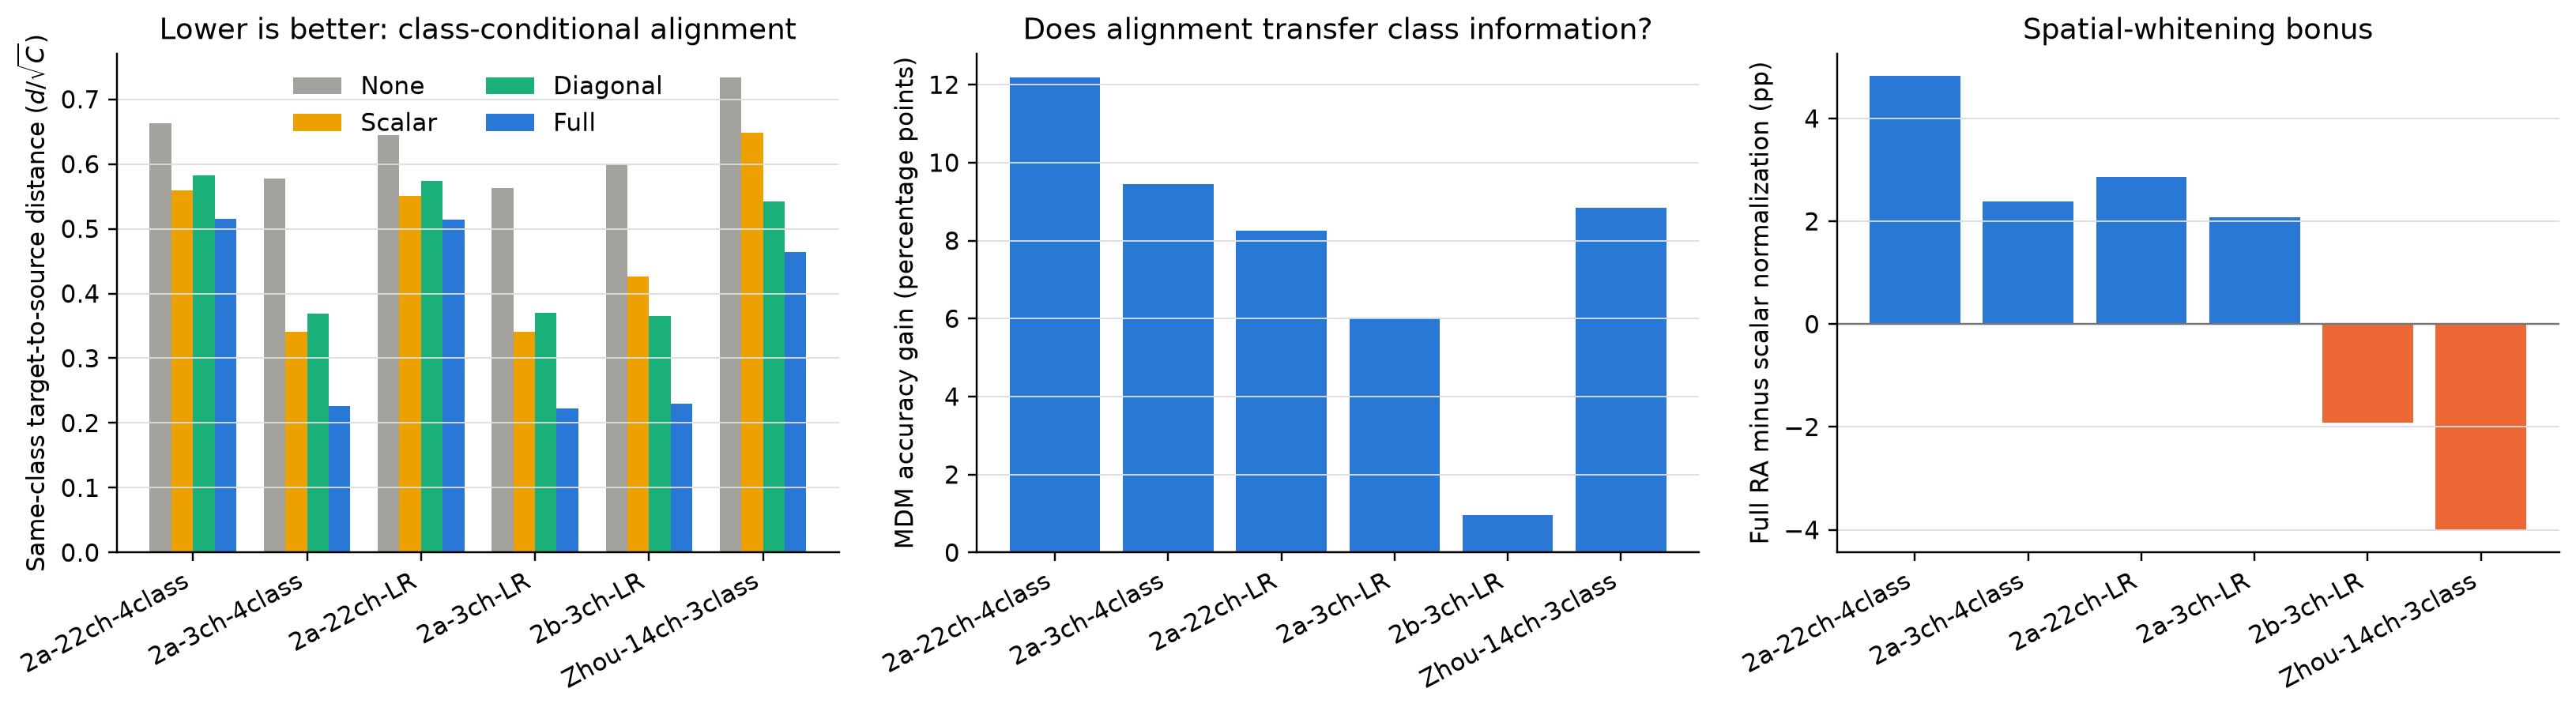

In [4]:
display(pd.DataFrame(controlled).T.round(4))
display(Image(filename=str(OUTPUT / 'ra_mechanism_summary.png')))

## Kiểm tra cơ chế quyết định: full spatial whitening hay chỉ scale normalization?

Scalar normalization chỉ bỏ overall amplitude. Phần `Full − Scalar` vì thế gần hơn với giá trị riêng của việc sửa spatial covariance/cross-channel mixing. Nếu số này dương trên 2a nhưng bằng 0 hoặc âm trên 2b/Zhou, đó là bằng chứng rằng spatial whitening hữu ích có điều kiện theo dataset—không phải cứ giảm domain distance nhiều là tăng accuracy.

In [5]:
mechanism = summary[[
    'config', 'mdm_gain_full_pp', 'mdm_full_minus_scalar_pp',
    'mdm_full_minus_diagonal_pp', 'p_mdm_none_vs_full',
    'p_mdm_scalar_vs_full',
]].copy()
display(mechanism.round(4))

main = mechanism.set_index('config')
print('BCI 2a full spatial bonus over scalar:', round(main.loc['2a-22ch-4class', 'mdm_full_minus_scalar_pp'], 2), 'pp')
print('BCI 2b full spatial bonus over scalar:', round(main.loc['2b-3ch-LR', 'mdm_full_minus_scalar_pp'], 2), 'pp')
print('Zhou full spatial bonus over scalar:', round(main.loc['Zhou-14ch-3class', 'mdm_full_minus_scalar_pp'], 2), 'pp')

,config,mdm_gain_full_pp,mdm_full_minus_scalar_pp,mdm_full_minus_diagonal_pp,p_mdm_none_vs_full,p_mdm_scalar_vs_full
0,2a-22ch-4class,12.1914,4.8225,8.5648,0.0039,0.3750
1,2a-22ch-LR,8.2562,2.8549,4.4753,0.0742,0.9102
2,2a-3ch-4class,9.4522,2.3920,8.0247,0.0078,0.3008
3,2a-3ch-LR,6.0185,2.0833,4.9383,0.0977,0.7422
4,2b-3ch-LR,0.9673,-1.9196,-0.7688,0.4961,0.0977
5,Zhou-14ch-3class,8.8333,-4.0000,0.1667,0.2500,0.2500


BCI 2a full spatial bonus over scalar: 4.82 pp
BCI 2b full spatial bonus over scalar: -1.92 pp
Zhou full spatial bonus over scalar: -4.0 pp


## Quy tắc diễn giải

- Không dùng việc fit-session mean trở thành identity làm bằng chứng; đó là hệ quả toán học của RA.
- Bằng chứng chính phải xuất hiện trên evaluation sessions và ở metric có điều kiện theo lớp.
- Nếu 2a-22ch cải thiện nhiều hơn 2a-3ch trong paired test, số chiều/spatial covariance là một cơ chế được dữ liệu ủng hộ.
- Nếu khác biệt chỉ xuất hiện giữa dataset nhưng không xuất hiện trong controlled 2a experiment, không được quy nguyên nhân cho số kênh.
- Đây là phân tích cơ chế input-level; kết luận cuối cùng vẫn cần đối chiếu với accuracy gain qua nhiều seed.